In [48]:
import xarray as xr #Import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point

In [49]:
sstpath = '/home/bward23/clim680/assignment2/sstv6.nc' #Open both data sets
dssst = xr.open_dataset(sstpath)
olrpath = '/home/bward23/clim680/assignment2/OLR-Monthly_v03r00_s197901_latest.nc'
dsolr = xr.open_dataset(olrpath)

In [50]:
dssst = dssst.sel(time = slice(dsolr['time'][0], None)) #Select the sea surface temp times that exist in the OLR dataset

sst = dssst["sst"] #Select SST and OLR data
olr = dsolr["olr"]

#Both measurements adjusted to have matching times (OLR timestamps in middle of month, SST timestamps at beginning of month)
sst = sst.assign_coords(time = pd.to_datetime(sst.time.dt.strftime("%Y-%m")))
olr = olr.assign_coords(time = pd.to_datetime(olr.time.dt.strftime("%Y-%m")))

In [51]:
sst = sst.assign_coords(lon = ((sst.lon + 180) % 360) - 180).sortby("lon") #Move both longitudes to be measured from -180 to 180
olr = olr.assign_coords(lon = ((olr.lon + 180) % 360) - 180).sortby("lon")

sst = sst.interp(lat = olr.lat, lon = olr.lon, method = "linear") #Interpolate data points to similar lons and lats between datasets

In [52]:
sst_mean = sst.mean(dim = 'time') #Means for both datasets
olr_mean = olr.mean(dim = 'time')

sst_anom = sst - sst_mean #Anomalies for both datasets
olr_anom = olr - olr_mean

sst_anom, olr_anom = xr.align(sst_anom, olr_anom, join = "inner") #Removes entries where times don't match between sst_anom and olr_anom

In [54]:
sst_std = sst_anom.std(dim = 'time') #Standard deviation of SST

warm_mask = sst_anom > sst_std #Warm anomaly, one standard deviation above mean SST
cold_mask = sst_anom < -sst_std #Cold anomaly, one standard deviation below mean SST
norm_mask = sst_anom < sst_std #Norm anomaly, within one standard deviation of mean SST
norm_mask = sst_anom > -sst_std

/home/bward23/miniforge3/envs/clim680/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [55]:
olr_warm = olr_anom.where(warm_mask) #SST mask applied to OLR anomalies
olr_cold = olr_anom.where(cold_mask)
olr_norm = olr_anom.where(warm_mask == False).where(cold_mask == False)

warm_composite = olr_warm.mean(dim = "time") #Averages all warm/cold data over time
cold_composite = olr_cold.mean(dim = "time")
norm_composite = olr_norm.mean(dim = "time")

color_limit = max(abs(warm_composite).max().item(),abs(cold_composite).max().item()) #Calculates the limit of the shared colorbar

In [56]:
warm_data, cyclic_lon = add_cyclic_point(warm_composite.values, coord = warm_composite.lon.values) #Cyclic points for warm and cold graph
cold_data, _ = add_cyclic_point(cold_composite.values, coord = cold_composite.lon.values)
norm_data, _ = add_cyclic_point(norm_composite.values, coord = norm_composite.lon.values)

In [57]:
nx = len(sst_anom.lon) #Calculate p-values for each cell
ny = len(sst_anom.lat)

p_warmarray = np.zeros((ny, nx))
p_coldarray = np.zeros((ny, nx))
p_normarray = np.zeros((ny, nx))

for i in range(nx): #Warm anomaly p-values
    for j in range(ny):
        r, p = pearsonr(sst_anom[:, j, i].values, warm_mask[:, j, i].values)
        p_warmarray[j, i] = p

for i in range(nx): #Cold anomaly p-values
    for j in range(ny):
        r, p = pearsonr(sst_anom[:, j, i].values, cold_mask[:, j, i].values)
        p_coldarray[j, i] = p

for i in range(nx): #Norm anomaly p-values
    for j in range(ny):
        r, p = pearsonr(sst_anom[:, j, i].values, norm_mask[:, j, i].values)
        p_normarray[j, i] = p

/tmp/ipykernel_76557/1628824329.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = pearsonr(sst_anom[:, j, i].values, warm_mask[:, j, i].values)
/tmp/ipykernel_76557/1628824329.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = pearsonr(sst_anom[:, j, i].values, cold_mask[:, j, i].values)
/tmp/ipykernel_76557/1628824329.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = pearsonr(sst_anom[:, j, i].values, norm_mask[:, j, i].values)


In [58]:
significant_warm = p_warmarray < 0.001 #Checking for p-values less than 0.001
significant_cold = p_coldarray < 0.001
significant_norm = p_normarray < 0.001

In [59]:
significant_warm, _ = add_cyclic_point(significant_warm, coord = warm_composite.lon.values) #Add the cyclic point to the statistical significance array
significant_cold, _ = add_cyclic_point(significant_cold, coord = cold_composite.lon.values)
significant_norm, _ = add_cyclic_point(significant_norm, coord = norm_composite.lon.values)

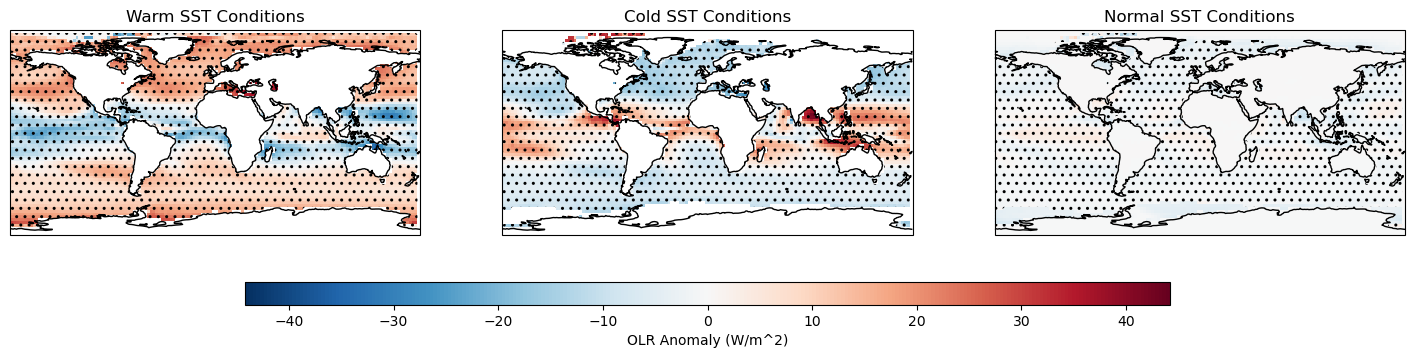

In [60]:
fig, axes = plt.subplots(1, 3, figsize = (18, 6), subplot_kw = {"projection": ccrs.PlateCarree()}) #Draw plots

plot_data = [warm_data, cold_data, norm_data] #Data expressed in a list format for easier plotting

significant_mask = [significant_warm, significant_cold, significant_norm]

titles = ["Warm SST Conditions", "Cold SST Conditions", "Normal SST Conditions"]

for ax, data, title, significant in zip(axes, plot_data, titles, significant_mask):

    mesh = ax.pcolormesh(cyclic_lon, warm_composite.lat, data, cmap = "RdBu_r", vmin = -color_limit,
        vmax = color_limit, transform = ccrs.PlateCarree()) #Plot OLR anomaly
    ax.coastlines(linewidth = 1) #Draw coastlines and set titles
    ax.set_title(title)

    ax.contourf(cyclic_lon, warm_composite.lat.values, significant, levels = [0.5, 1.5], colors = "none",
        hatches = [".."], transform = ccrs.PlateCarree()) #Plot statistical significance hatches

cbar = fig.colorbar(mesh, ax = axes, orientation = "horizontal", pad = 0.10, fraction = 0.05, aspect = 40) #Creates a shared colorbar for both maps
cbar.set_label("OLR Anomaly (W/m^2)")

plt.show() #Interestingly, when calculating significance by comparing sst_anom with olr_anom, the regions of non-significant data exist along the north-south
#boundary extremes of the ITCZ

#The general location of the maximal anomalies is mirrored across the graphs, but the maximum and minimum anomaly values don't match up as well